In [1]:
# General Python Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# CNN Layers
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    AveragePooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)

# Data Augmentation
from tensorflow.keras.layers import (
    RandomFlip,
    RandomRotation,
    RandomZoom,
    RandomContrast,
    RandomTranslation
)

# Model Evaluation
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

There are two stages of EDA for an image classification project - file level EDA and image/content EDA. The file-level EDA is conducted before loading the images into the TensorFlow. At this stage, we are examining the dataset as files. We want to determine:

1. Number of images per class
2. file types / extensions
3. corrupted images
4. duplicate files
5. image dimensions
6. aspect ratios
7. colour modes/channels
8. file sizes

### 1. Inspect the actual File

We want to inspect the folders directly to find the number of classes and files

In [2]:
base_dir = "PetImages"

for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir, class_name)

    if os.path.isdir(class_path):
        print(f"\n{class_name}")
        print("Number of files", len(os.listdir(class_path)))


Cat
Number of files 12499

Dog
Number of files 12499


### 2. Count the number of images in each class

In [3]:
class_counts = {}

for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir, class_name)

    if os.path.isdir(class_path):
        class_counts[class_name] = len(os.listdir(class_path))

print(class_counts)

{'Cat': 12499, 'Dog': 12499}


#### Visualize the classes

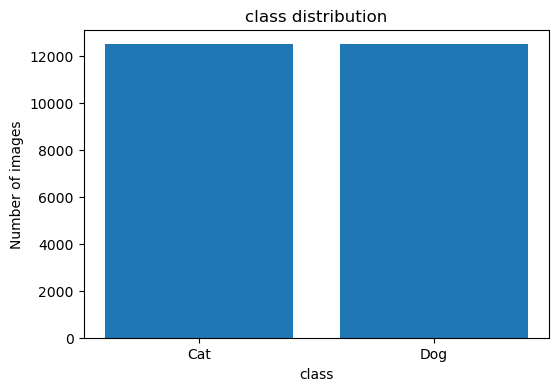

In [4]:
plt.figure(figsize = (6, 4))

plt.bar(class_counts.keys(), class_counts.values())
plt.xlabel("class")
plt.ylabel("Number of images")
plt.title("class distribution")
plt.show()

### 3. Check for Corrupt Images

The code goes through every class folder, examine every image file, and identify files that cannot be properly opened or verified as images.

In [5]:
#We will use Pillow

from PIL import Image

In [6]:
# Get a set of valid extensions
valid_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".gif"
)

# Get a list of corrupt images
corrupted_images = []
invalid_files = []

for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir, class_name)

    #if it is not a folder, move to the next
    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):

        #Create a path to each file in the class folder
        file_path = os.path.join(class_path, filename)

        # Remove invalid files
        if not filename.lower().endswith(valid_extensions):
            invalid_files.append(file_path)
            continue

        try:
            with Image.open(file_path) as img:
                img.verify() #Pillow verify if image is valid and not corrupt
        except Exception:
            corrupted_images.append(file_path)

print("Corrupted images: ", len(corrupted_images))
print("Invalid files: ", len(invalid_files))

C:\ProgramData\anaconda3\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Corrupted images:  0
Invalid files:  0


In [7]:
# # The code below was used to verify the problem with the code above
# valid_extensions = (
#     ".jpg",
#     ".jpeg",
#     ".png",
#     ".bmp",
#     ".gif"
# )

# corrupted_images = []

# for class_name in os.listdir(base_dir):

#     class_path = os.path.join(base_dir, class_name)

#     if not os.path.isdir(class_path):
#         continue

#     for filename in os.listdir(class_path):

#         file_path = os.path.join(class_path, filename)

#         if not filename.lower().endswith(valid_extensions):
#             continue

#         try:
#             with Image.open(file_path) as img:
#                 img.verify()

#         except Exception as e:
#             corrupted_images.append((file_path, str(e)))


# print("Corrupted images:", len(corrupted_images))

# # Display the first 10 errors
# for file_path, error in corrupted_images[:10]:
#     print(file_path)
#     print("Error:", error)
#     print()

#### Removing Corrupt and invalid files

In [8]:
# delete invalid files
# for image_path in invalid_files:
#     #Check if path exists
#     if os.path.exists(image_path):
#         print("Remove: ", image_path)
#         os.remove(image_path)

# print("invalid files removed")

### 4. Check Image Dimension

In [9]:
image_dimension = []

for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        file_path = os.path.join(class_path, filename)

        try:
            with Image.open(file_path) as img:
                width, height = img.size

                image_dimension.append({
                    "class": class_name,
                    "width": width,
                    "height": height
                })

        except Exception:
            pass #Means do nothing for the current pass

#### Convert to Dataframe

In [10]:
dimensions_df = pd.DataFrame(image_dimension)
dimensions_df.head()

,class,width,height
0,Cat,500,375
1,Cat,300,281
2,Cat,489,500
3,Cat,403,500
4,Cat,150,150


In [11]:
dimensions_df.describe()

,width,height
count,24998.000000,24998.000000
mean,404.447196,360.989239
std,108.999959,97.005417
min,4.000000,4.000000
25%,323.000000,302.000000
50%,448.000000,375.000000
75%,500.000000,421.000000
max,500.000000,500.000000


NOTE: If some of the images have smaller sizes than the specified image_size when we upload the images, Tensorflow will enlarge the smaller images (upsampling). When this happens, image may become blurry. The implications include:

1. Loss of image details. When an image is enlarged, TensorFlow estimates pixel values between existing pixels using an interpolation method.
For example: Original image: 64 × 64 = 4,096 pixels, Resized image: 224 × 224 = 50,176 pixels. The resized image contains over 12 times as many pixel positions, but it does not contain 12 times as much original visual information. A CNN may still learn useful features, such as the general shape of a cat's ears or a dog's face. However, fine details such as individual hairs or small facial features may remain unclear.

2. The CNN may learn less useful feature. Convolutional layers learn patterns such as edges, textures, shapes, and object parts. If low-resolution images are heavily blurred or pixelated, some of these patterns may be harder to identify. Consequently, the model may struggle to distinguish visually similar cats and dogs.

### 5. Examine Width and Height Distribution

This helps to understand the original dataset before resizing

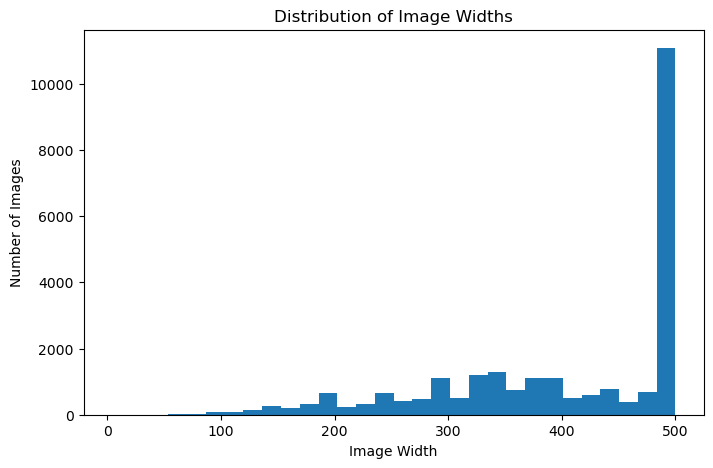

In [12]:
# Plot the graph for the width

plt.figure(figsize=(8, 5))

plt.hist(
    dimensions_df["width"],
    bins=30
)

plt.xlabel("Image Width")
plt.ylabel("Number of Images")
plt.title("Distribution of Image Widths")

plt.show()

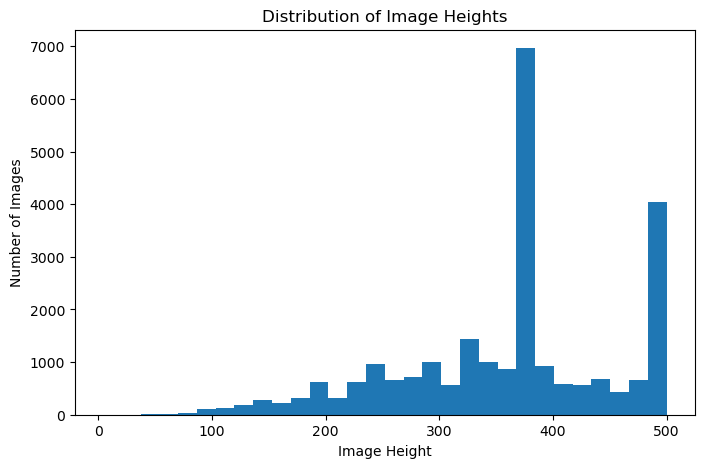

In [13]:
# Plot the graph for the height

plt.figure(figsize=(8, 5))

plt.hist(
    dimensions_df["height"],
    bins=30
)

plt.xlabel("Image Height")
plt.ylabel("Number of Images")
plt.title("Distribution of Image Heights")

plt.show()

### 6. Examine the Aspect Ratio

Examining the aspect ratio can reveal very wide or very narrow images. For instance, if an image with 16:9 aspect ratio is resized to 224 x 224, the image may become distorted because the width and height are forced into the same dimensions. 

In [14]:
dimensions_df["aspect_ratio"] = (
    dimensions_df["width"] / 
    dimensions_df["height"]
)

In [15]:
#describe
dimensions_df["aspect_ratio"].describe()

count    24998.000000
mean         1.156402
std          0.291399
min          0.306000
25%          0.929066
50%          1.269036
75%          1.333333
max          5.939394
Name: aspect_ratio, dtype: float64

NOTE: The TensorFlow's image_dataset_from_directory() supports alternative resizing approaches including:

1. crop_to_aspect_ratio = True: Crop the image to the target aspect ratio before resizing.
2. pad_to_aspect_ratio = True: add padding to preserve the original aspect ratio before resizing

The two parameters above are included in the image_dataset_from_directory(). The padding preserves the image proportions but introduces borders where needed. Cropping avoids distortion but may remove parts of the image. The best choice depends on your dataset. 

When calculating the aspect ratio, smaller values like 0.3060 indicates that an image is more taller than it is wide (the image is approx 3.27 times taller than it is wide). An aspect ratio of 5.9394 means the image is extremely wider than it is tall (means the image is like six times wider than it is tall). 

In other words, aspect ratio less than 1 means portrait, greater than 1 means landscape, and 1 means squre image. 

### 7. Check image modes / colour channels

This tells whether the image is RGB, RGBA or any other mode. 

In [16]:
from collections import Counter

image_modes = []

for class_name in os.listdir(base_dir):

    class_path = os.path.join(base_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):

        file_path = os.path.join(class_path, filename)

        try:
            with Image.open(file_path) as img:
                image_modes.append(img.mode)

        except Exception:
            pass

mode_counts = Counter(image_modes)

print(mode_counts)

C:\ProgramData\anaconda3\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Counter({'RGB': 24931, 'P': 57, 'L': 5, 'CMYK': 3, 'RGBA': 2})


##### 7a. Exclude non RGB images

We want to exclude no RGB images because the CNN is expecting images with three channels - not anything above or below

In [17]:
#shutil is designed for bulk operations on files
import shutil
#from PIL import Image

# Original dataset directory
base_dir = "PetImages"

# New directory for RGB images only
rgb_only_dir = "PetImages_RGB_Only"

# Supported image file extensions
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

# Track the results
mode_counts = Counter() #Count the mode
copied_count = 0 #Count number copied
excluded_count = 0 #Count number excluded
unreadable_count = 0 #Count number of unreadable files

# Process each class folder, e.g. Cat and Dog
for class_name in os.listdir(base_dir):

    class_path = os.path.join(base_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    # Create the corresponding output class folder
    output_class_path = os.path.join(rgb_only_dir, class_name)
    os.makedirs(output_class_path, exist_ok=True)

    #Open file to read extension
    for filename in os.listdir(class_path):

        if not filename.lower().endswith(valid_extensions):
            continue

        file_path = os.path.join(class_path, filename)

        #Open file to read the mode of the file
        try:
            with Image.open(file_path) as img:

                # Load the image data to detect decoding problems
                img.load()

                mode_counts[img.mode] += 1

                # Keep only images already in RGB mode
                if img.mode == "RGB":

                    output_path = os.path.join(
                        output_class_path, filename
                    )

                    #Copy a file
                    shutil.copy2(file_path, output_path)
                    copied_count += 1

                else:
                    excluded_count += 1

        except Exception as e:
            unreadable_count += 1
            print("Unreadable image:", file_path, "|", e)

print("\nImage modes found:", mode_counts)
print("RGB images copied:", copied_count)
print("Non-RGB images excluded:", excluded_count)
print("Unreadable images skipped:", unreadable_count)


Image modes found: Counter({'RGB': 24931, 'P': 57, 'L': 5, 'CMYK': 3, 'RGBA': 2})
RGB images copied: 24931
Non-RGB images excluded: 67
Unreadable images skipped: 0


##### 7b. Load the dataset

In [18]:
import tensorflow as tf

rgb_dataset = tf.keras.utils.image_dataset_from_directory(
    rgb_only_dir,
    image_size=(224, 224),
    batch_size=32,
    color_mode="rgb",
    shuffle=True
)

print("Class names:", rgb_dataset.class_names)

Found 24931 files belonging to 2 classes.
Class names: ['Cat', 'Dog']


##### 7c. Check if tensorflow can read all images

In [19]:
total_images = 0

for images, labels in rgb_dataset:
    total_images += images.shape[0]

print("Successfully loaded images:", total_images)

InvalidArgumentError: {{function_node __wrapped__IteratorGetNext_output_types_2_device_/job:localhost/replica:0/task:0/device:CPU:0}} Number of channels inherent in the image must be 1, 3 or 4, was 2
	 [[{{node decode_image/DecodeImage}}]] [Op:IteratorGetNext] name: 

The error above indicates there are some files that tensorflow cannot read even though they escaped PILLOW. TensorFlow is encountering a file that it cannot recognize as a supported image format while iterating through rgb_dataset.

##### 7d. Identify files that the tensor flow cannot decode

In [20]:
scan_dir = rgb_only_dir  # Change if rgb_dataset uses another directory

decode_failures = []
checked_count = 0

for class_name in os.listdir(scan_dir):
    class_path = os.path.join(scan_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        file_path = os.path.join(class_path, filename)

        if not filename.lower().endswith(valid_extensions):
            continue

        checked_count += 1

        try:
            #Read each file
            image_bytes = tf.io.read_file(file_path)

            #Decode each file
            image = tf.io.decode_image(
                image_bytes,
                channels=3,
                expand_animations=False
            )

            # Force TensorFlow to evaluate the decoded image
            image.numpy()

        except Exception as e:
            decode_failures.append(file_path)
            print("FAILED:", file_path)
            print("Reason:", str(e).splitlines()[0])
            print("-" * 60)

print("Files checked:", checked_count)
print("Files TensorFlow could not decode:", len(decode_failures))

FAILED: PetImages_RGB_Only\Cat\10404.jpg
Reason: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Unknown image file format. One of JPEG, PNG, GIF, BMP, WebP required. [Op:DecodeImage] name: 
------------------------------------------------------------
FAILED: PetImages_RGB_Only\Cat\4351.jpg
Reason: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input size should match (header_size + row_size * abs_height) but they differ by 2 [Op:DecodeImage] name: 
------------------------------------------------------------
FAILED: PetImages_RGB_Only\Dog\11233.jpg
Reason: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Number of channels inherent in the image must be 1, 3 or 4, was 2 [Op:DecodeImage] name: 
------------------------------------------------------------
FAILED: PetImages_RGB_Only\Dog\11912.jpg
Reason: {{function_node __wrapped__DecodeImage_device_/job:l

##### 7e. If files fail, create a clean RGB dataset

If files fail, you can create a clean RGB dataset. Rather than immediately deleting the failed files, you can re-encode every readable image as a new JPEG in a separate directory. This standardizes the image format and colour mode while preserving the originals.

In [21]:
clean_dir = "PetImages_Clean_RGB"
converted_total = 0
failed_files = []

for class_name in os.listdir(scan_dir):
    class_path = os.path.join(scan_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    output_class = os.path.join(clean_dir, class_name)
    os.makedirs(output_class, exist_ok=True)

    for filename in os.listdir(class_path):
        if not filename.lower().endswith(valid_extensions):
            continue

        file_path = os.path.join(class_path, filename)

        try:
            #Open file for reading
            with Image.open(file_path) as img:
                img.load()
                rgb_image = img.convert("RGB") #Convert

                # Use a unique output filename
                output_name = f"image_{converted_total:06d}.jpg"
                output_path = os.path.join(output_class, output_name)

                rgb_image.save(output_path, "JPEG", quality=95)
                converted_total += 1

        except Exception as e:
            failed_files.append((file_path, str(e)))
            print("Could not convert:", file_path, "|", e)

print("Successfully re-encoded:", converted_total)
print("Files that could not be converted:", len(failed_files))

Successfully re-encoded: 24931
Files that could not be converted: 0


##### 7e. Delete Failed Files

In [22]:
# deleted_count = 0
# already_missing_count = 0
# failed_delete_count = 0

# for file_path in decode_failures:

#     try:
#         if os.path.isfile(file_path):
#             os.remove(file_path)
#             deleted_count += 1
#             print("Deleted:", file_path)
#         else:
#             already_missing_count += 1
#             print("File not found:", file_path)

#     except OSError as e:
#         failed_delete_count += 1
#         print("Could not delete:", file_path, "|", e)

# print("\nDeletion summary")
# print("Files deleted:", deleted_count)
# print("Already missing:", already_missing_count)
# print("Deletion failures:", failed_delete_count)

### 8. Check file sizes

Extremely small files may deserve inspection

In [23]:
file_sizes = []

for class_name in os.listdir(clean_dir):

    class_path = os.path.join(clean_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):

        file_path = os.path.join(class_path, filename)

        try:
            size_kb = os.path.getsize(file_path) / 1024

            file_sizes.append({
                "class": class_name,
                "filename": filename,
                "size_kb": size_kb
            })

        except Exception:
            pass

# Convert it to dataframe
file_sizes_df = pd.DataFrame(file_sizes)
# Describe the file sizes
file_sizes_df["size_kb"].describe()

count    24931.000000
mean        46.283076
std         21.406969
min          0.666992
25%         32.090820
50%         44.647461
75%         58.071777
max        166.824219
Name: size_kb, dtype: float64

### 9. Look for duplicate images

If the same image appears multiple times, the CNN may effectively see the same example repeatedly and may not generalize. If duplicate ends in both training and test sets, there may be data leakage

In [24]:
# The simple first check is using file hashes
# the hashlib library generates a hash value for a file
# This is useful to identifying duplicate images
# Two images may be the same but with different file names
# The file hash help us detect these duplicates

import hashlib

In [25]:
def get_file_hash(file_path):

    with open(file_path, "rb") as f:
        #md5 is one of the hashfunctions provided by hashlib
        return hashlib.md5(f.read()).hexdigest()

In [26]:
hashes = {}

for class_name in os.listdir(clean_dir):

    class_path = os.path.join(clean_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):

        file_path = os.path.join(class_path, filename)

        try:
            file_hash = get_file_hash(file_path)

            if file_hash in hashes:
                print(
                    "Duplicate:",
                    file_path,
                    "<->",
                    hashes[file_hash]
                )
            else:
                hashes[file_hash] = file_path

        except Exception:
            pass

Duplicate: PetImages_Clean_RGB\Cat\image_002188.jpg <-> PetImages_Clean_RGB\Cat\image_001893.jpg
Duplicate: PetImages_Clean_RGB\Cat\image_003202.jpg <-> PetImages_Clean_RGB\Cat\image_000306.jpg
Duplicate: PetImages_Clean_RGB\Cat\image_003526.jpg <-> PetImages_Clean_RGB\Cat\image_000062.jpg
Duplicate: PetImages_Clean_RGB\Cat\image_003980.jpg <-> PetImages_Clean_RGB\Cat\image_002670.jpg
Duplicate: PetImages_Clean_RGB\Cat\image_005095.jpg <-> PetImages_Clean_RGB\Cat\image_000403.jpg
Duplicate: PetImages_Clean_RGB\Cat\image_005722.jpg <-> PetImages_Clean_RGB\Cat\image_001329.jpg
Duplicate: PetImages_Clean_RGB\Cat\image_006305.jpg <-> PetImages_Clean_RGB\Cat\image_005169.jpg
Duplicate: PetImages_Clean_RGB\Cat\image_006460.jpg <-> PetImages_Clean_RGB\Cat\image_005962.jpg
Duplicate: PetImages_Clean_RGB\Cat\image_006562.jpg <-> PetImages_Clean_RGB\Cat\image_001171.jpg
Duplicate: PetImages_Clean_RGB\Cat\image_006628.jpg <-> PetImages_Clean_RGB\Cat\image_004248.jpg
Duplicate: PetImages_Clean_RGB

### 10. Randomly Visualize the Image

This is used to randomly inspect images from each class. You are looking for things such as: incorrect labels, very blurry images, screenshots, drawings, cartoons, animals that are barely visible, extreme lighting, images containing both cats and dogs.

In [27]:
import random

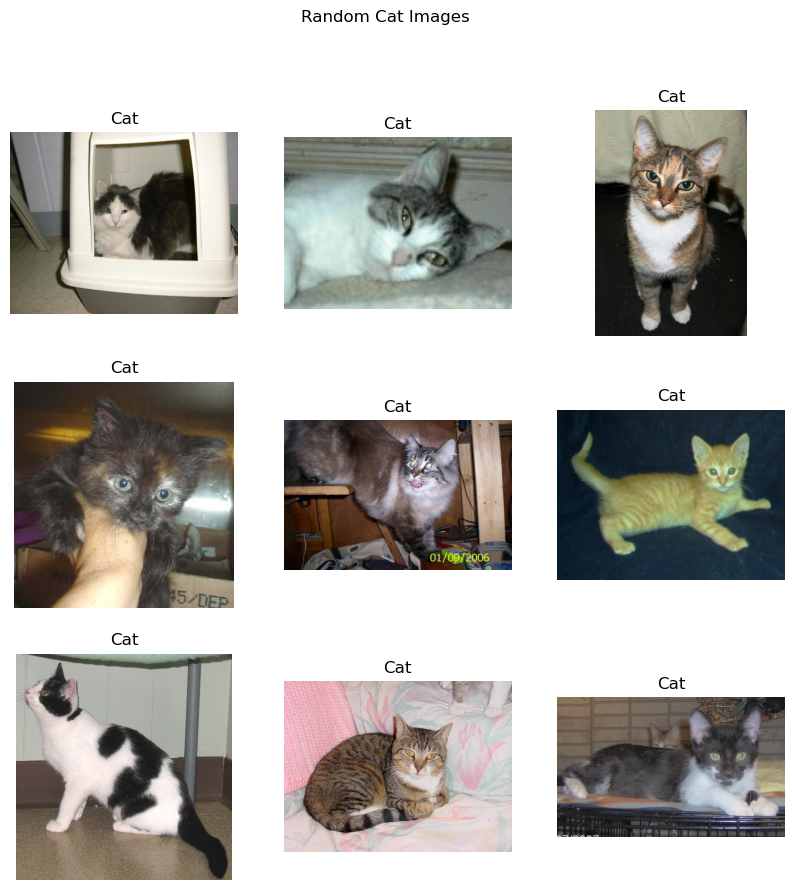

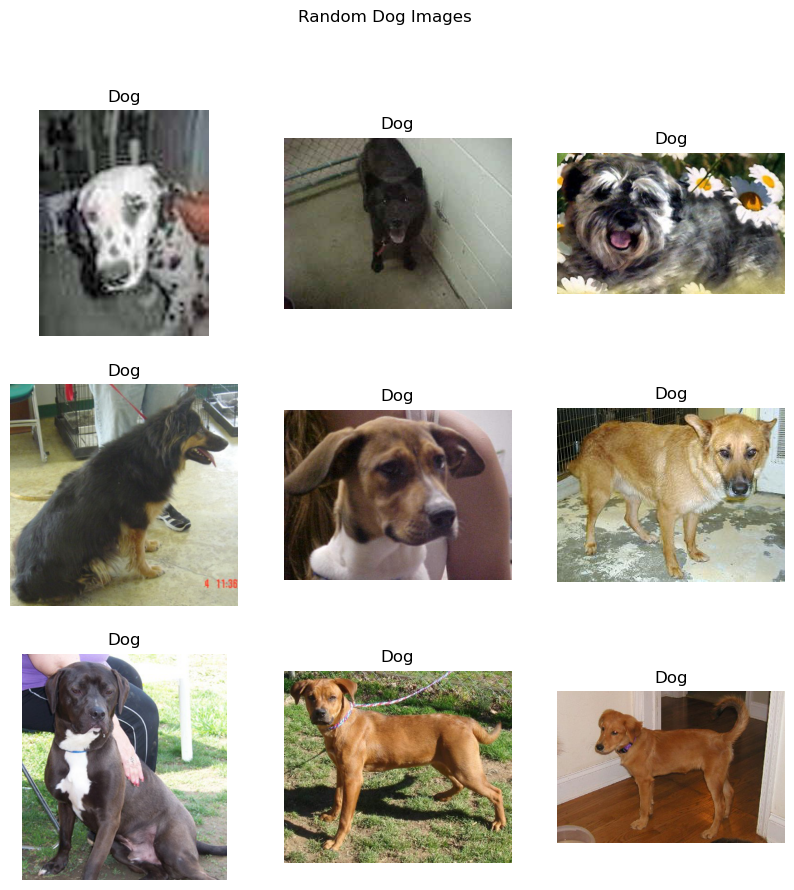

In [28]:
for class_name in ["Cat", "Dog"]:

    class_path = os.path.join(clean_dir, class_name)

    files = os.listdir(class_path)

    selected_files = random.sample(
        files,
        min(9, len(files))
    )

    plt.figure(figsize=(10, 10))

    for i, filename in enumerate(selected_files):

        file_path = os.path.join(
            class_path,
            filename
        )

        img = Image.open(file_path)

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(img)

        plt.title(class_name)

        plt.axis("off")

    plt.suptitle(f"Random {class_name} Images")

    plt.show()

Do not clean away legitimate variation. This is where image EDA differs from ordinary tabular data cleaning. You should not automatically remove:

1. blurry images
2. different image sizes
3. different backgrounds
4. different lighting
5. different poses
6. different orientations

Some of these are actually useful variations that help the CNN generalization

You can remove:

1. invalid files
2. corrupted files
3. duplicate
4. irrelevant files
5. incorrectly labeled file while preserving legitimate variations

## CNN Specific EDA

This is where we investigate what the CNN will actually receive

### Upload the images

To upload the images, we need to establish the folder structure because image_dataset_from_directory() expects a particular structure - each class must hold its own images in a folder. In this case, there must be a dog folder and a cat folder. 

To establish the folder structure, we can use the os.listdir() function

In [29]:
# Establish the folder structure

print(os.listdir("PetImages_Clean_RGB"))

['Cat', 'Dog']


The output indicates the folder structure is tensorflow friendly.

In [30]:
# Upload the image using image_dataset_from_directory
from tensorflow.keras.utils import image_dataset_from_directory


petImages = image_dataset_from_directory(
    "PetImages_Clean_RGB",
    image_size = (224, 224),
    batch_size = 32,
    shuffle = True,
    seed = 42
)

Found 24931 files belonging to 2 classes.


In [31]:
#Check the class names
print(petImages.class_names)

['Cat', 'Dog']


In [32]:
#Get the shape of images in a batch
for images, labels in petImages.take(1):
    print("images shape", images.shape)
    print("label shape", labels.shape)

images shape (32, 224, 224, 3)
label shape (32,)


In [33]:
# To get individual shape

for images, labels in petImages.take(1):
    for i in images:
        print(i.shape)

(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)


In [34]:
class_names = petImages.class_names

In [35]:
# To show with the labels
# To get individual shape

#The labels[i].shape returns () - scaler label with no dim
#It means each label has a single class label

for images, labels in petImages.take(1):
    for i in range(len(images)):
        print(images[i].shape, labels[i].shape)

(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()
(224, 224, 3) ()


The labels[i].shape reurns () for each image because it is a scalar label with no dimension. The label shape () means that each image has a single class label, typically an integer such as 0 or 1 for binary classification. Each individual label is a scaler - labels[i].shape is TensorShape([]) (NOTE: this () is the same as (1,)), while the batch shape is - labels.shape is TensorShape([32]). Therefore, labels.shape describes all labels in the batch: (32,), while labels[i].shape describes one label: ()

### Visualize some of the images

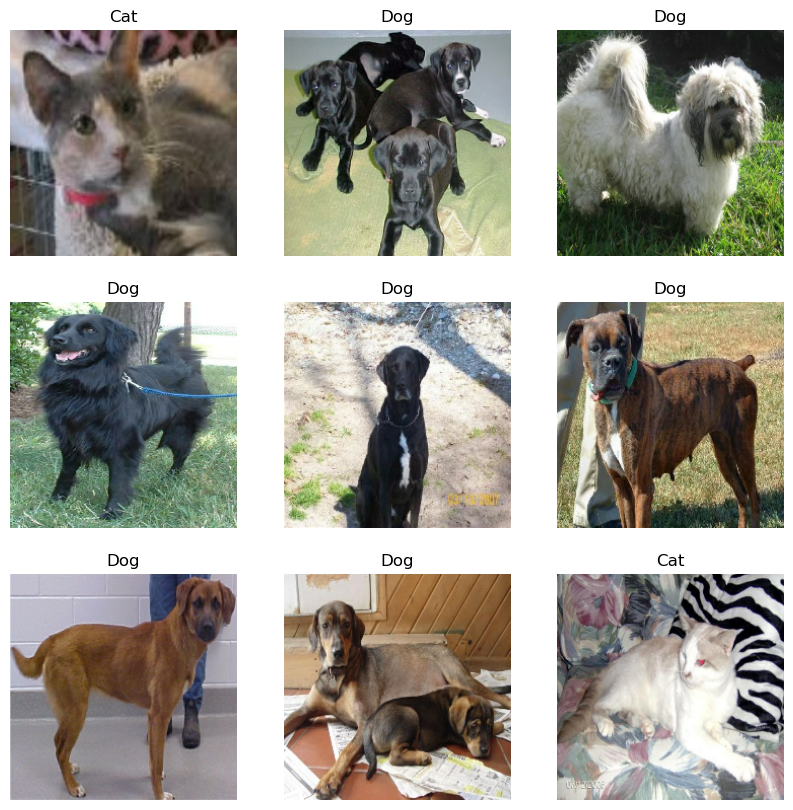

In [36]:
plt.figure(figsize=(10, 10))

for images, labels in petImages.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(petImages.class_names[labels[i]])
        plt.axis("off")

### Pixel-level EDA - Investigate Actual Pixel values

In [37]:
import tensorflow as tf

In [38]:
for images, labels in petImages.take(1):

    #Without converting to array, it will return tensorflow shape
    print("Minimum:", tf.reduce_min(images).numpy())
    print("Maximum:", tf.reduce_max(images).numpy())
    print("Mean:", tf.reduce_mean(images).numpy())
    print("Std:", tf.math.reduce_std(images).numpy())

Minimum: 0.0
Maximum: 255.0
Mean: 108.44607
Std: 62.455578


NOTE: The standard deviation tells us how spread out the pixel values are around their mean. 

### Plot the Overall Pixel Intensity Distribution

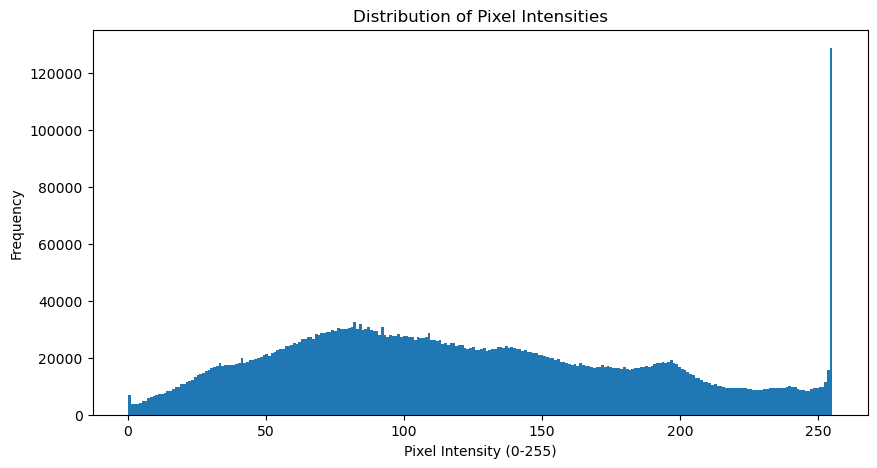

In [39]:
# Get one batch of images
for images, labels in petImages.take(1):

    # Convert the image tensor to a NumPy array
    pixel_values = images.numpy().flatten()

    # Plot the histogram
    plt.figure(figsize=(10, 5))

    plt.hist(pixel_values, bins=256, range=(0, 255))

    plt.title("Distribution of Pixel Intensities")
    plt.xlabel("Pixel Intensity (0-255)")
    plt.ylabel("Frequency")

    plt.show()

#### Others:

In [40]:
#### Visualize the red, green, and blue channels separately
#### Compare cats and dogs separately
#### Compare distribution before and after normalization

This gap in the pixel values informs the step for scaling

## Preprocessing

This phase will include:

1. Resizing the image if not done
2. scale pixel values
3. split the dataset
4. apply augmentation to training images

In [41]:
# We have already resized

### Determine the number of batches

In [42]:
print("Number of batches:", 
      tf.data.experimental.cardinality(petImages).numpy())

Number of batches: 780


### Split into training, validation and test sets

The three sets have different purposes:

1. training set: Learns the model weights and filters
2. validation set: monitors learning and helps choose model settings
3. evaluates the final model on data not used for training or model selection

In [43]:
total_batches = tf.data.experimental.cardinality(
    petImages
).numpy()

train_batches = int(0.8 * total_batches)
val_batches = int(0.1 * total_batches)

train_ds = petImages.take(train_batches)

remaining_ds = petImages.skip(train_batches)

val_ds = remaining_ds.take(val_batches)
test_ds = remaining_ds.skip(val_batches)

#print number of batches in training
print("Training batches:", 
      tf.data.experimental.cardinality(train_ds).numpy())

#print number of batches in validation
print("Validation batches:", 
      tf.data.experimental.cardinality(val_ds).numpy())

#print number of batches in test
print("Test batches:", 
      tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 624
Validation batches: 78
Test batches: 78


** Teaching note: ** This is a convenient demonstration of take() and skip(), but it is not the most rigorous splitting method. For a formal experiment, split the individual image file paths into training, validation and test sets before batching, preferably with stratification by class. This helps preserve class proportions and avoids accidentally splitting related or duplicate images across subsets.

### Improve the Input Pipeline

TensorFlow can prefetch batches while the model processes the current batch. This may improve training throughput.

In [44]:
# AUTOTUNE = tf.data.AUTOTUNE

# train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
# val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
# test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

### Apply Data Augmentation

In [45]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
], name="data_augmentation")

### Visualize the Augmentation

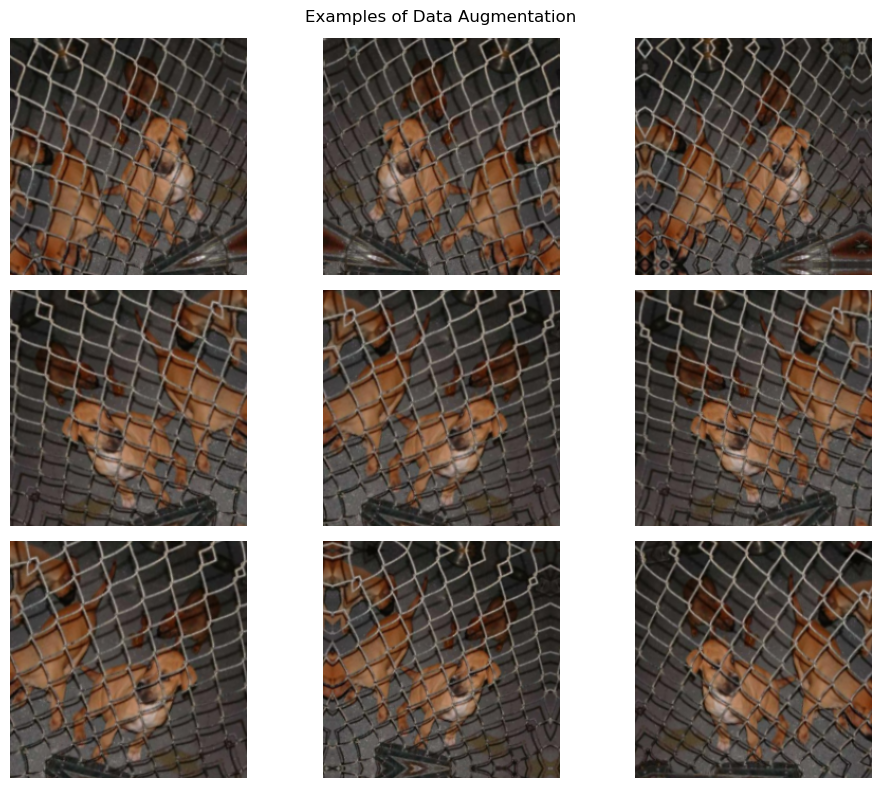

In [46]:
for images, labels in train_ds.take(1):
    sample_image = images[0]

    plt.figure(figsize=(10, 8))

    for i in range(9):
        augmented_image = data_augmentation(
            tf.expand_dims(sample_image, axis=0),
            training=True
        )[0]

        plt.subplot(3, 3, i + 1)
        plt.imshow(
            tf.cast(
                tf.clip_by_value(augmented_image, 0, 255),
                tf.uint8
            )
        )
        plt.axis("off")

    plt.suptitle("Examples of Data Augmentation")
    plt.tight_layout()
    plt.show()

### Build and train the CNN

In [47]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    data_augmentation,
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        128, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

In [48]:
#Compile the Model

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

1. Adam: updates model weights using gradient-based optimization.
2. Binary cross-entropy: measures the difference between the model's predictions and the true binary labels.
3. Accuracy: measures the proportion of correctly classified images.

In [49]:
# Train the model

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/2
624/624 ━━━━━━━━━━━━━━━━━━━━ 469s 749ms/step - accuracy: 0.5793 - loss: 0.6801 - val_accuracy: 0.6398 - val_loss: 0.6287
Epoch 2/2
624/624 ━━━━━━━━━━━━━━━━━━━━ 524s 840ms/step - accuracy: 0.6754 - loss: 0.6022 - val_accuracy: 0.7440 - val_loss: 0.5221


#### Save the Model

In [50]:
model.save("catsDogsModel.keras")

print("Model saved successfully.")

Model saved successfully.


#### Load the Model

In [51]:
loaded_model = tf.keras.models.load_model("catsDogsModel.keras")

print("Model loaded successfully.")

Model loaded successfully.


#### Save the Training History

In [52]:
import json

with open("training_history.json", "w") as file:
    json.dump(history.history, file)

print("Training history saved.")

Training history saved.


#### Load the history

In [53]:
with open("training_history.json", "r") as file:
    saved_history = json.load(file)

#### Visualization

We did not use saved_history.history["accuracy"] because saved_history is a Python dictionary, not a Keras History object. The initial history is a python object, hence we need the history.history[]

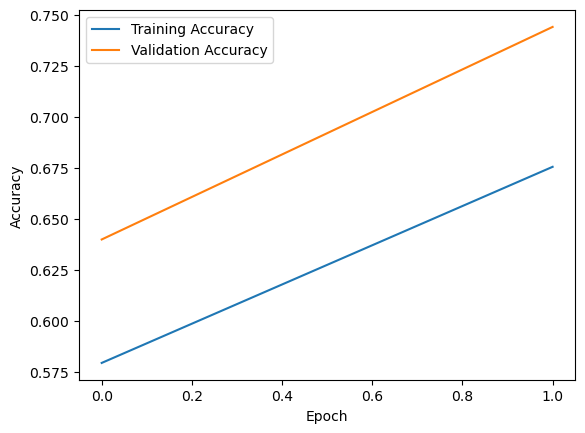

In [54]:
#USe the training history to plot accuracy

plt.plot(saved_history["accuracy"], label="Training Accuracy")
plt.plot(saved_history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

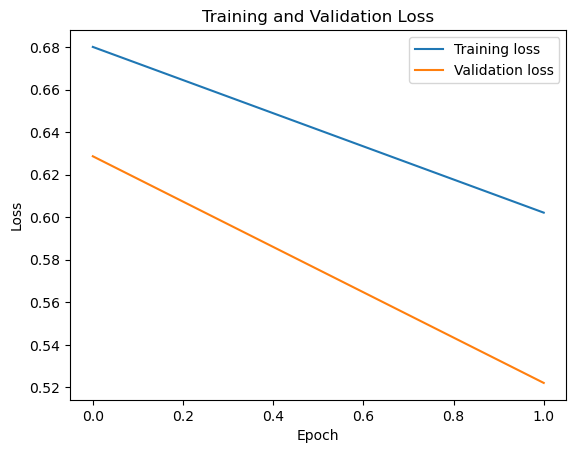

In [55]:
# Loss Plot

plt.plot(saved_history["loss"], label="Training loss")
plt.plot(saved_history["val_loss"], label="Validation loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

Interpret the plots as follows:
- Both accuracy curves improve: the model is learning useful patterns.
- Training accuracy rises while validation accuracy stalls or falls: possible overfitting.
- Both accuracies remain low: possible underfitting, insufficient training, or a data/preprocessing issue.
- Training and validation losses both decrease: generally a positive sign, though final performance must still be measured on the test set.
These are diagnostic patterns rather than absolute rules.

Without saving the history, we can use the code below

In [56]:
# plt.figure(figsize=(12, 5))

# # Accuracy plot
# plt.subplot(1, 2, 1)
# plt.plot(history.history["accuracy"], label="Training accuracy")
# plt.plot(history.history["val_accuracy"], label="Validation accuracy")
# plt.title("Training and Validation Accuracy")
# plt.xlabel("Epoch")
# plt.ylabel("Accuracy")
# plt.legend()

# # Loss plot
# plt.subplot(1, 2, 2)
# plt.plot(history.history["loss"], label="Training loss")
# plt.plot(history.history["val_loss"], label="Validation loss")
# plt.title("Training and Validation Loss")
# plt.xlabel("Epoch")
# plt.ylabel("Loss")
# plt.legend()

# plt.tight_layout()
# plt.show()

### Prediction and Classification

For this model, the output is a single sigmoid score:
- A score below 0.5 predicts class index 0.
- A score equal to or above 0.5 predicts class index 1.
For example, if class_names is ['Cat', 'Dog'], a score of 0.85 predicts Dog, while 0.20 predicts Cat. These scores are model outputs; they should not automatically be interpreted as perfectly calibrated probabilities.

##### A. Clssify Single Image

In [57]:
from tensorflow.keras.utils import load_img, img_to_array

image_path = "image_012972.jpg"  # Replace with your image path

# Load and resize the image
img = load_img(
    image_path,
    target_size=(224, 224)
)

# Convert the image to a numerical array
img_array = img_to_array(img)

# Add a batch dimension: (224, 224, 3) -> (1, 224, 224, 3)
img_array = np.expand_dims(img_array, axis=0)

In [58]:
# Predict the image
score = model.predict(img_array, verbose=0)[0][0]

In [59]:
# Convert the score into a class prediction
predicted_index = 1 if score >= 0.5 else 0
predicted_class = class_names[predicted_index]

print("Predicted class:", predicted_class)
print("Raw sigmoid score:", round(float(score), 4))



Predicted class: Dog
Raw sigmoid score: 0.8748


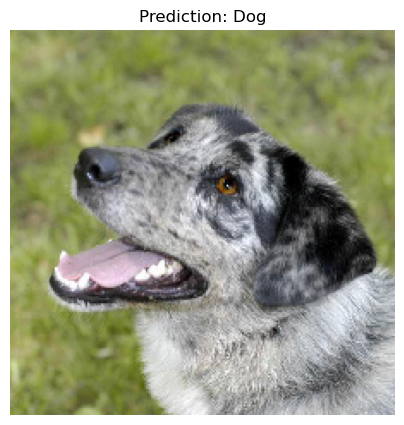

In [60]:
# Display the image and prediction
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(f"Prediction: {predicted_class}")
plt.axis("off")
plt.show()

##### B. Classify Multiple Images

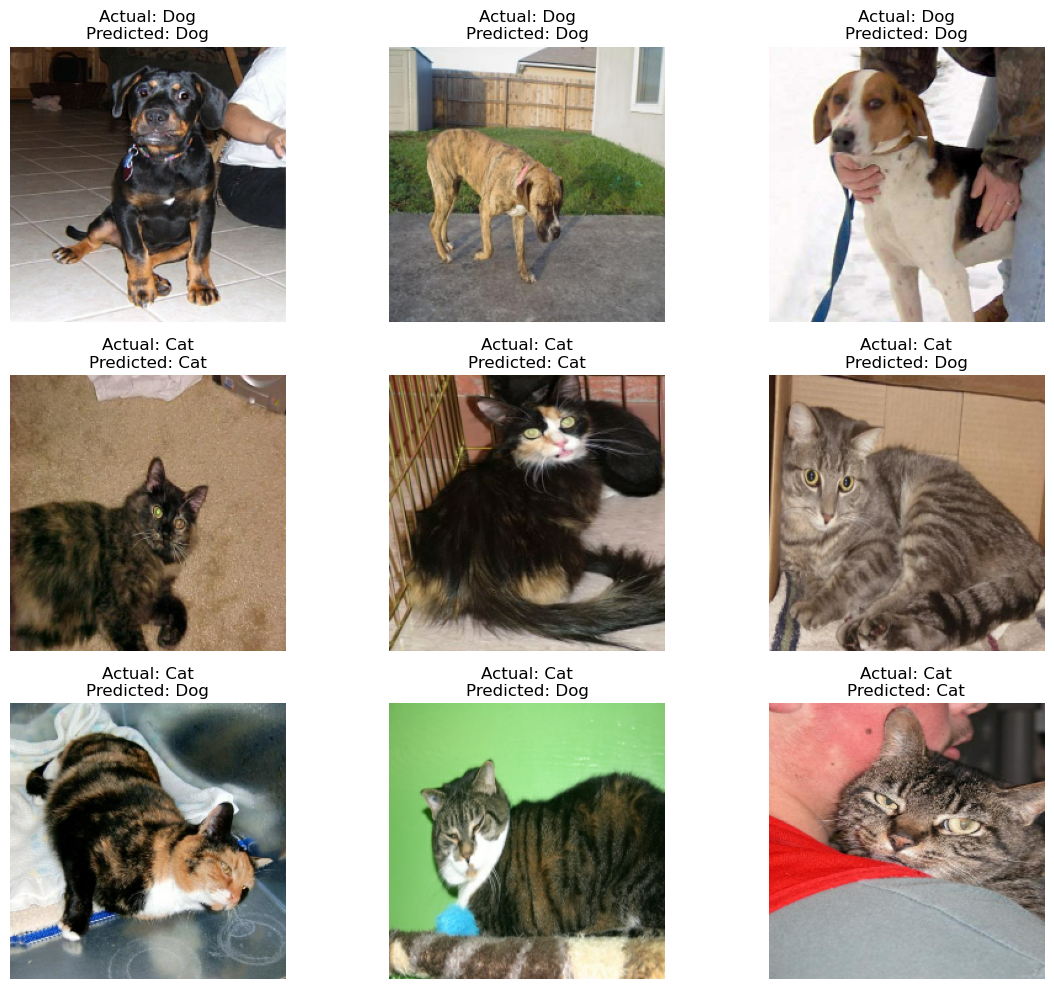

In [61]:
for images, labels in test_ds.take(1):
    predictions = model.predict(images, verbose=0)

    plt.figure(figsize=(12, 10))

    for i in range(min(9, len(images))):
        score = float(predictions[i][0])

        predicted_index = 1 if score >= 0.5 else 0
        actual_index = int(labels[i].numpy())

        predicted_name = class_names[predicted_index]
        actual_name = class_names[actual_index]

        plt.subplot(3, 3, i + 1)
        plt.imshow(
            tf.cast(
                tf.clip_by_value(images[i], 0, 255),
                tf.uint8
            )
        )

        plt.title(
            f"Actual: {actual_name}\nPredicted: {predicted_name}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

### Evaluate the Trained Model

##### A. Calculate the Test Loss and Accuracy

In [62]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy (%): {test_accuracy * 100:.2f}%")

78/78 ━━━━━━━━━━━━━━━━━━━━ 27s 218ms/step - accuracy: 0.7272 - loss: 0.5377
Test loss: 0.5377
Test accuracy: 0.7272
Test accuracy (%): 72.72%


Test accuracy tells us what proportion of test images the model classified correctly. Test loss provides another measure of prediction error based on binary cross-entropy. Neither metric alone reveals which class the model struggles with, so we will calculate additional measures.

### Generate Prediction for the Entire Test Set

In [63]:
y_true = []
y_pred = []
y_scores = []

for images, labels in test_ds:
    # Obtain sigmoid scores
    scores = model.predict(images, verbose=0).ravel()

    # Convert scores into class indices
    predicted_labels = (scores >= 0.5).astype(int)

    # Store actual labels, predicted labels and scores
    y_true.extend(labels.numpy().astype(int))
    y_pred.extend(predicted_labels)
    y_scores.extend(scores)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_scores = np.array(y_scores)

print("Number of test images:", len(y_true))

Number of test images: 2467


### Calculate the Precision, Recall and F1-score

In [64]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

         Cat     0.7251    0.7403    0.7326      1240
         Dog     0.7319    0.7164    0.7241      1227

    accuracy                         0.7284      2467
   macro avg     0.7285    0.7284    0.7283      2467
weighted avg     0.7285    0.7284    0.7284      2467



The report provides several metrics:
Metric	and Meaning
- Precision:	Of the images predicted as a particular class, how many actually belong to that class?
- Recall:	Of all actual images belonging to a class, how many did the model correctly identify?
- F1-score:	Harmonic mean of precision and recall.
- Support:	Number of actual test images in each class.

For example, high Dog precision means that images predicted as Dog are usually dogs. High Dog recall means the model identifies a large proportion of all actual dog images. The report also includes macro and weighted averages. Macro average treats the classes equally; weighted average accounts for the number of examples in each class.

### Confusion Matrix

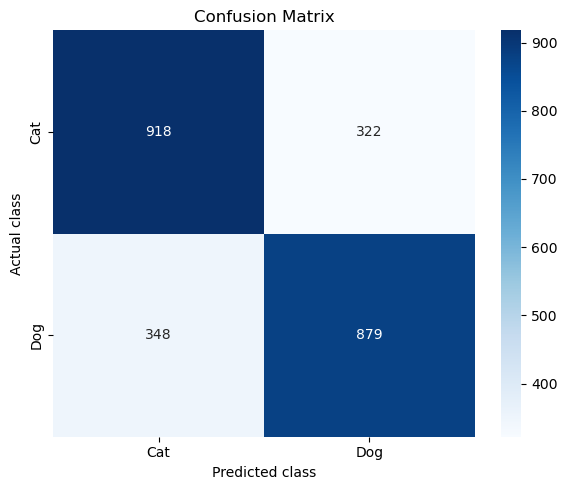

In [65]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

### The ROC Curve

The ROC curve shows how the true-positive rate and false-positive rate change as the classification threshold varies. An ROC-AUC closer to 1 indicates stronger ability to rank positive examples above negative ones. A score around 0.5 indicates performance close to random ranking. ROC-AUC evaluates ranking ability across thresholds, whereas accuracy evaluates classifications at the selected threshold

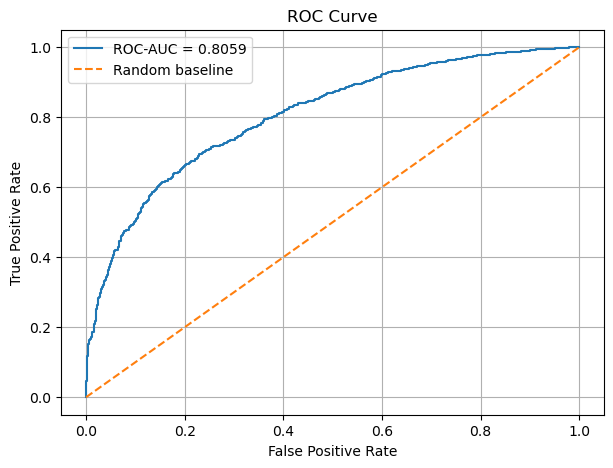

ROC-AUC: 0.8059


In [66]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_true, y_scores)
auc_score = roc_auc_score(y_true, y_scores)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {auc_score:.4f}"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

print(f"ROC-AUC: {auc_score:.4f}")